## Introduction to Jupyter Notebooks

Welcome to the Jupyter Hub! Jupyter Notebooks provide an interactive environment where you can mix text, equations, programming code, and visual outputs. Here’s a quick guide on how to use it:

### Cells

A notebook is made up of cells. Each cell can contain text or code. There are two main types of cells:

- **Markdown cells**: These contain formatted text written in Markdown and can include images, links, and embedded HTML. This cell is a Markdown cell. You can double-click on it to see the source code. After editing, you can run the cell to render the text.
- **Code cells**: These contain code to be executed by the kernel (the notebook's computational engine). In this notebook, you'll be using Python code cells.

### Running Cells

To run a cell:

1. Click on the cell to select it.
2. Press `Shift + Enter` to execute the cell content. Alternatively, you can use the "Run" button in the toolbar.

Sometimes you'll need to restart. To do this, click on the "Kernel" menu and select "Restart Kernel and Clear All Outputs".

### Editing Cells

To edit any cell, double-click on it. If it’s a code cell, you can start typing your code directly. For markdown cells, after double-clicking, you'll see the Markdown text. You can make changes and run the cell to see the updated format.

### Saving Your Work

You can save your work by clicking on the floppy disk icon in the toolbar or by pressing `Ctrl + S` on your keyboard. For mac users, press `Cmd + S`.

### Adding and Deleting Cells

You can add new cells by clicking the "+" icon on the toolbar. To delete a cell, select it and click the scissors icon, or press `D` twice on your keyboard when in command mode (press `Esc` to enter command mode).

### Getting Help

For help with any Python function, type the function name followed by a question mark `?` and run the cell (e.g., `print?`).

### That's it!

---


### Tutorial

In this tutorial I will show you how to use the code for the Bucket Model. Sometimes you will see `FutureWarning` messages. You can ignore these messages.

### Importing Libraries

First you need to import the code for the Bucket Model. You can do this by running the cell below. Click `Shift + Enter` to run the cell. The green tick mark indicates that the cell has been run.


In [85]:
from bucket_model import BucketModel  # This where the Bucket Model is defined
from bucket_model_optimizer import (
    BucketModelOptimizer,
)  # This class allows you to calibrate the model parameters and evaluate the model performance
from data_processing import (
    preprocess_data,
    train_validate_split,
)  # This class allows you to preprocess the data and split it into training and validation sets

from bucket_model_plotter import (
    plot_water_balance,  # This script contains functions to plot the results of the model
    plot_Q_Q,
    plot_ECDF,
    plot_boxplots,
    plot_monthly_boxplot,
    plot_timeseries,
    plot_parameter_kde,
)

import pandas as pd  # This is a library for data manipulation.

import warnings  # This is a library to handle warnings

warnings.filterwarnings("ignore")  # This is to ignore warnings

### Setting up

In the next cell you need to set the path to the data file, the path to the output file and the catchment area. You can do this by editing the cell below and running it.


In [86]:
CATCHMENT = "GSTEIG"

path_to_file = "data/GSTEIG_INPUT.txt"
catchment_area = 384.2  # km^2 (Ex1: basin_gsteig.shp polygon area, QGIS)

# WEEK 1: Develop a daily water balance model

### Getting the data

In the next cell you will pre-process the data. This will store the data into a pandas dataframe. A pandas dataframe is like an Excel spreadsheet; it is a 2-dimensional table where you can organize, manipulate, and analyze data easily. You need to provide the catchment area for the transformation of the units from m^3/s to mm/day.


In [87]:
data = preprocess_data(
    path_to_file=path_to_file, catchment_area=catchment_area, filter_dates=(1986, 1999)
)  # This is to preprocess the data

# Let's have a look at the data
data

,day,P_mix,T_max,T_min,Q
date,,,,,
1986-01-01,1,3.8,-3.4,-12.8,0.513408
1986-01-02,2,0.4,-1.4,-8.8,0.535896
1986-01-03,3,5.7,-3.9,-8.8,0.532298
1986-01-04,4,4.2,-6.5,-14.8,0.525776
1986-01-05,5,4.1,-3.5,-13.2,0.526676
...,...,...,...,...,...
1999-12-27,361,8.1,-0.4,-8.0,1.772077
1999-12-28,362,33.8,-4.5,-9.8,1.430930
1999-12-29,363,8.8,-8.3,-10.8,1.282957


### Initialize the model and set the catchment properties.


In [88]:
# Initialize the BucketModel with initial parameter guesses

parameters = {
    "k": 0.5,  # degree-day snowmelt parameter
    "S_max": 35,  # max soil water storage
    "fr": 0.8,  # fraction of impermeable area at soil saturation
    "rg": 7,  # mean residence time of water in groundwater
    "snow_threshold_temp": 0,  # threshold temperature for snowfall
}

catchment_properties = {
    "lapse_rate": 0.5 / 100,  # °C/m
    "basin_mean_elevation": 2035,  # m.a.s.l (Ex1: zonal mean of dem_region.tif = 2034.9 m)
    "hru_mean_elevation": 2035,  # m.a.s.l (lumped: same as basin mean)
    "snowmelt_temp_threshold": 0,  # °C
    "latitude": 46.59,  # °N (Ex1: basin polygon centroid, WGS84)
}

bucket = BucketModel(
    parameters
)

# Set the catchment properties
bucket.set_catchment_properties(
    catchment_properties
)

Catchment properties set:
  Lapse rate: 0.005 °C/m
  Basin mean elevation: 2035 m.a.s.l.
  HRU mean elevation: 2035 m.a.s.l.
  Snowmelt temperature threshold: 0 °C
  Latitude: 46.59°


### You can also change the initial conditions of the model


In [89]:
bucket.change_initial_conditions(soil_moisture=10, groundwater=100)

Initial conditions updated:
  Soil moisture: 10 mm
  Groundwater storage: 100 mm
  Snow cover: 0.0 mm


### Run the model


In [90]:
first_run_results = bucket.run(data=data)

# Let's have a look at them
first_run_results.head()

,PET,ET,Q_s,Q_gw,Total_Runoff,Snow_accum,S,S_gw,Snow_melt,Ice_melt,S_ice,Rain,Snow,Precip
date,,,,,,,,,,,,,,
1986-01-01,0.186879,0.053394,0.0,14.285714,14.285714,3.8,9.946606,85.714286,0.0,0.0,0.0,0.0,3.8,3.8
1986-01-02,0.233601,0.066387,0.0,12.244898,12.244898,4.2,9.880219,73.469388,0.0,0.0,0.0,0.0,0.4,0.4
1986-01-03,0.214099,0.060439,0.0,10.495627,10.495627,9.9,9.819781,62.973761,0.0,0.0,0.0,0.0,5.7,5.7
1986-01-04,0.156020,0.043774,0.0,8.996252,8.996252,14.1,9.776007,53.977509,0.0,0.0,0.0,0.0,4.2,4.2
1986-01-05,0.186260,0.052025,0.0,7.711073,7.711073,18.2,9.723982,46.266437,0.0,0.0,0.0,0.0,4.1,4.1


### Visualize the results

To save the plots just add the `output_destination` parameter to the `plot` function. For example:

```python
output_destination = 'images/first_wat_bal.png'
plot_water_balance(results=first_run_results, output_destination=output_destination)
```


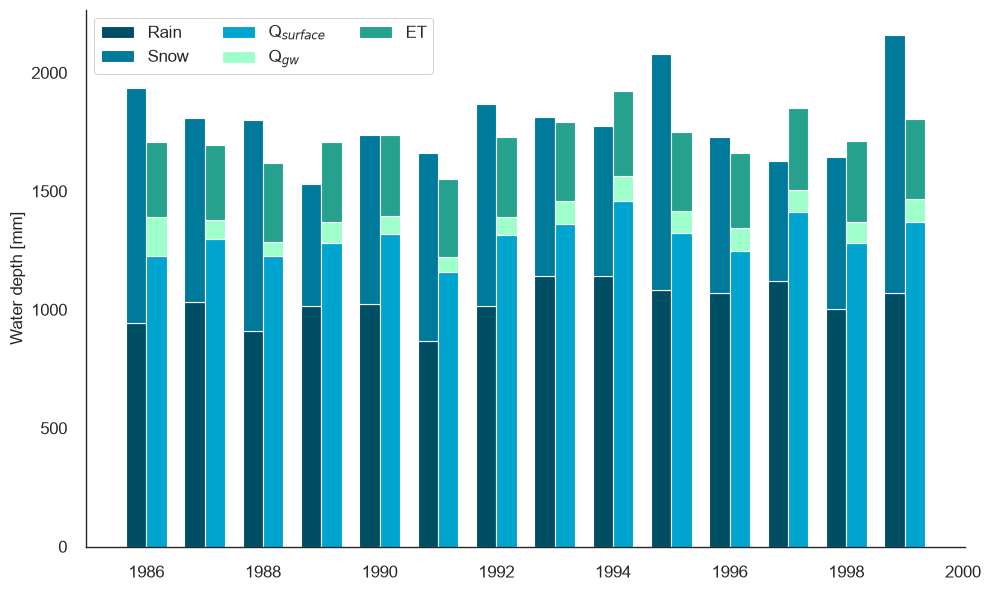

In [91]:
plot_water_balance(results=first_run_results)

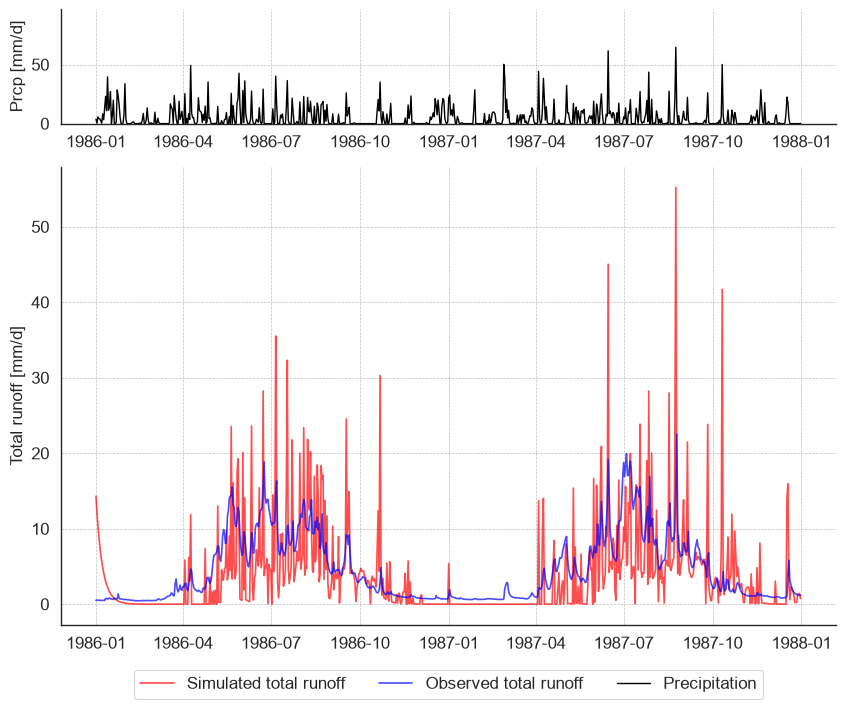

In [92]:
plot_timeseries(
    results=first_run_results,
    observed=data,
    start_year="1986",
    end_year="1987",
    palette=["red", "blue", "black"],
    plot_precipitation=True,
    
)

### Let's look at some stats:


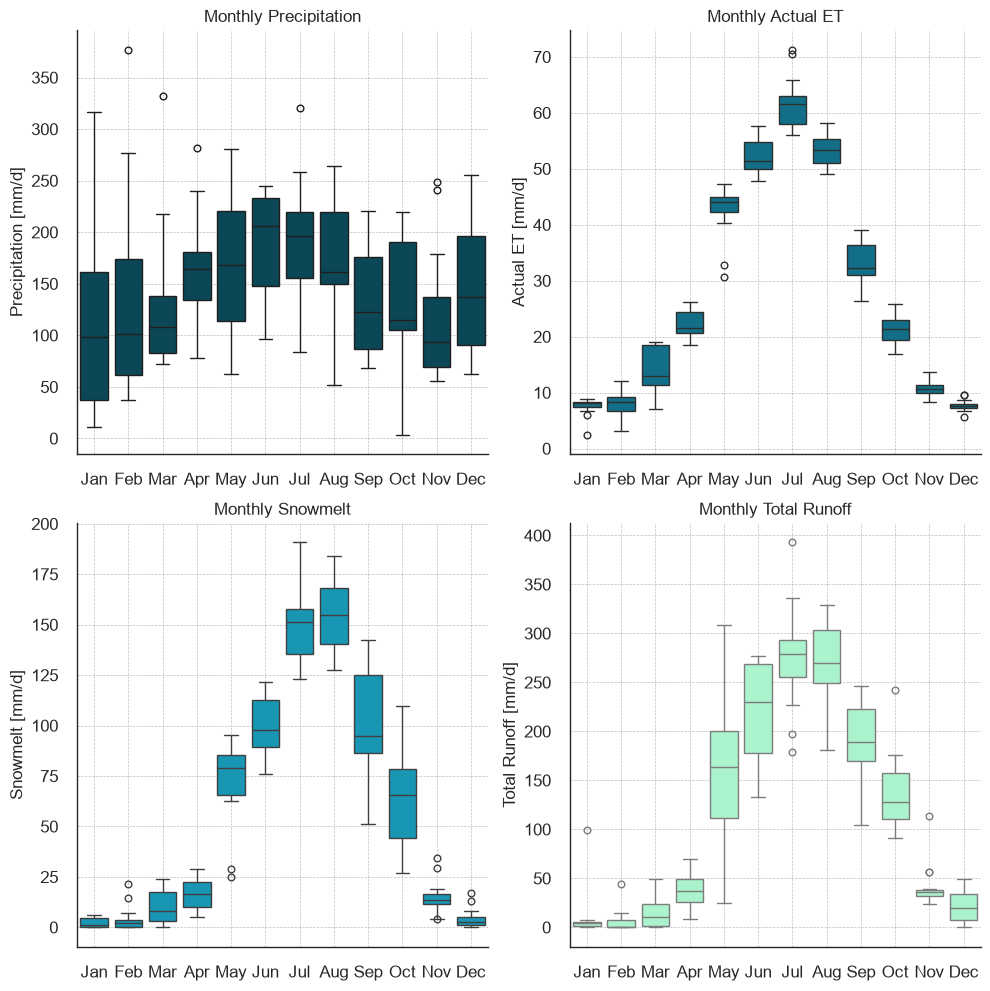

In [93]:
plot_monthly_boxplot(results=first_run_results, figsize=(10, 10))

In [94]:
import metrics  # goodness-of-fit functions (same as used by the optimizer in Week 2)


def score_run(results, observed, metric_names=("nse", "log_nse", "kge", "rmse", "mae", "pbias")):
    """Goodness-of-fit of the simulated total runoff against the observed Q [mm/d]."""
    valid = observed["Q"].notna()
    sim = results.loc[valid, "Total_Runoff"]
    obs = observed.loc[valid, "Q"]
    return pd.Series({name: getattr(metrics, name)(sim, obs) for name in metric_names})


score_run(first_run_results, data).round(3)

nse        -0.587
log_nse    -0.204
kge         0.300
rmse        5.027
mae         3.047
pbias     -11.532
dtype: float64

### Uncomment the following lines to see all other plots:

The plots have some more customization options. You can have a look at the `bucket_model_plotter.py` file to see all the options.


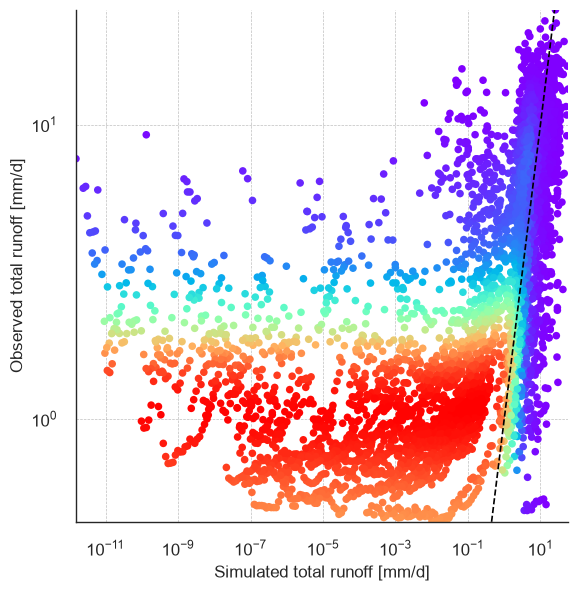

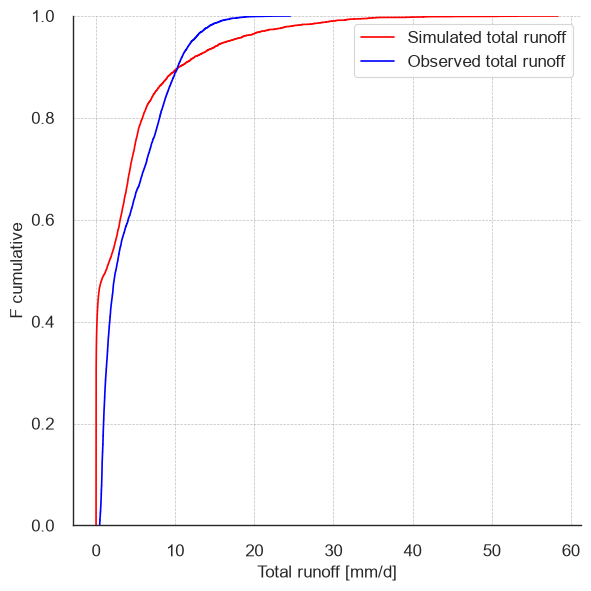

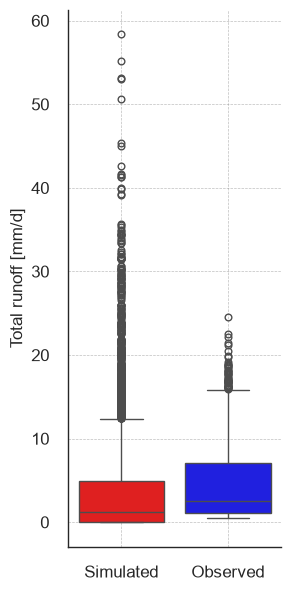

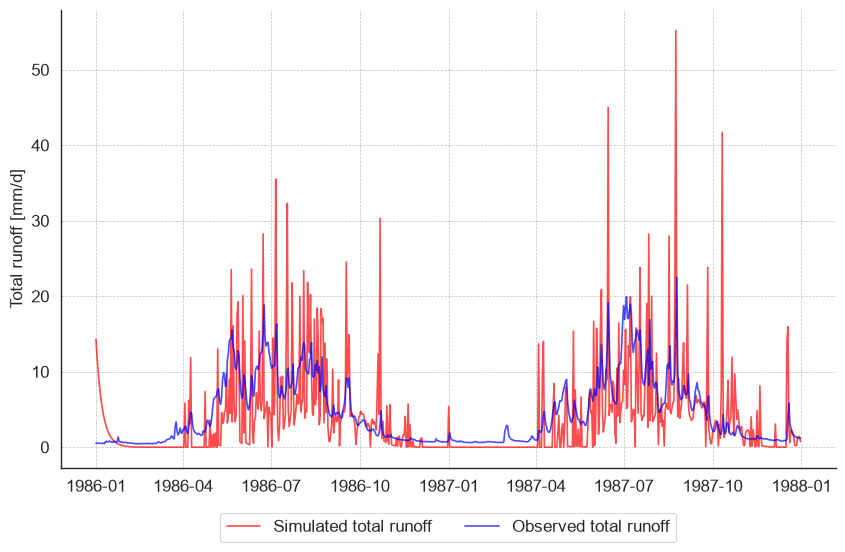

In [95]:
plot_Q_Q(results=first_run_results, observed=data)

plot_ECDF(results=first_run_results, observed=data, palette=["red", "blue"])

plot_boxplots(results=first_run_results, observed=data, palette=["red", "blue"])

plot_timeseries(
    results=first_run_results,
    observed=data,
    start_year="1986",
    end_year="1987",
    palette=["red", "blue"],
    monthly=False,
)

### Update the parameters

The first guess is not very impressive. Let's try another guess and see how it goes.


In [96]:
bucket.change_initial_conditions(soil_moisture=5, groundwater=100)

Initial conditions updated:
  Soil moisture: 5 mm
  Groundwater storage: 100 mm
  Snow cover: 998.7473030391432 mm


In [97]:
second_guess = {
    "k": 1.25,
    "k_ice": 0.5,
    "S_max": 10,
    "fr": 0.2,
    "rg": 30,
    "snow_threshold_temp": 1,
}

bucket.update_parameters(second_guess, verbose=True)

Parameters updated:
  k: 1.25 mm/°C/day
  S_max: 10 mm
  fr: 0.2
  rg: 30 days
  snow_threshold_temp: 1 °C


In [98]:
# You can check that the parameters have been updated by printing the model:
print(bucket)

### Spin-up

The initial conditions (snow, soil moisture, groundwater) are not known on 1 January 1986. From the second guess on, the model is therefore started in 1981 (`SPINUP_START`) and run through the spin-up period; only 1986-1999 is kept and evaluated, so the states on 1 January 1986 are set by the model itself.

In [99]:
# Spin-up: run from SPINUP_START, evaluate only the period of `data` (1986-1999)
SPINUP_START = 1981
data_spinup = preprocess_data(
    path_to_file=path_to_file, catchment_area=catchment_area, filter_dates=(SPINUP_START, 1999)
)


def run_with_spinup(model, data_spinup, eval_index):
    """Run the model over the spin-up + evaluation period and keep only the evaluation period."""
    return model.run(data=data_spinup).loc[eval_index]

In [100]:
# Run with spin-up (see above): results cover 1986-1999 only
second_run_results = run_with_spinup(bucket, data_spinup, data.index)

In [101]:
score_run(second_run_results, data).round(3)

nse        0.658
log_nse    0.650
kge        0.819
rmse       2.334
mae        1.621
pbias     -6.547
dtype: float64

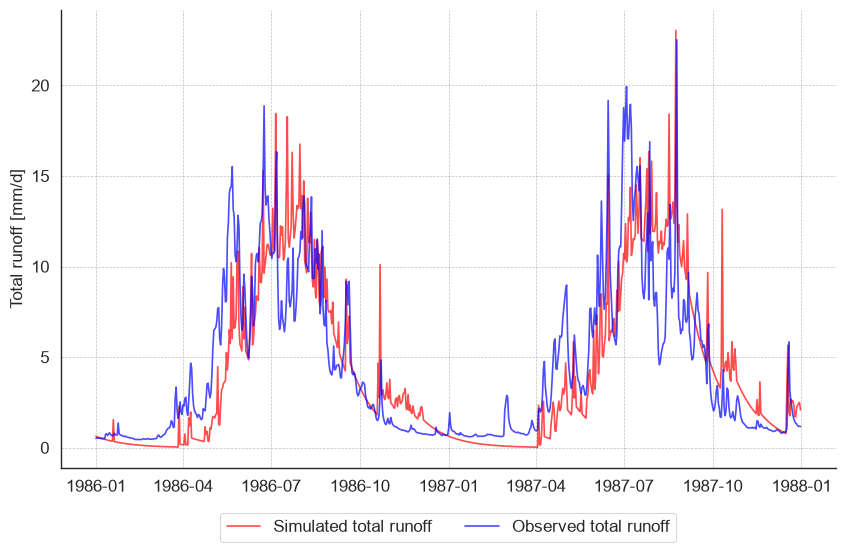

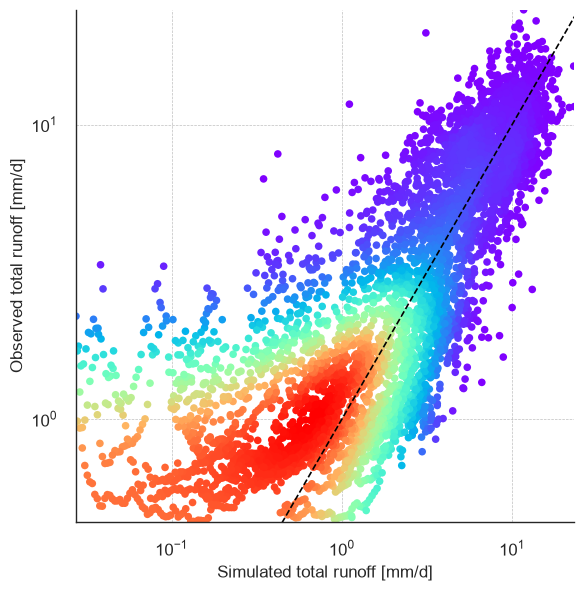

In [102]:
plot_timeseries(
    results=second_run_results,
    observed=data,
    start_year="1986",
    end_year="1987",
    palette=["red", "blue"],
    monthly=False,
)
plot_Q_Q(results=second_run_results, observed=data)

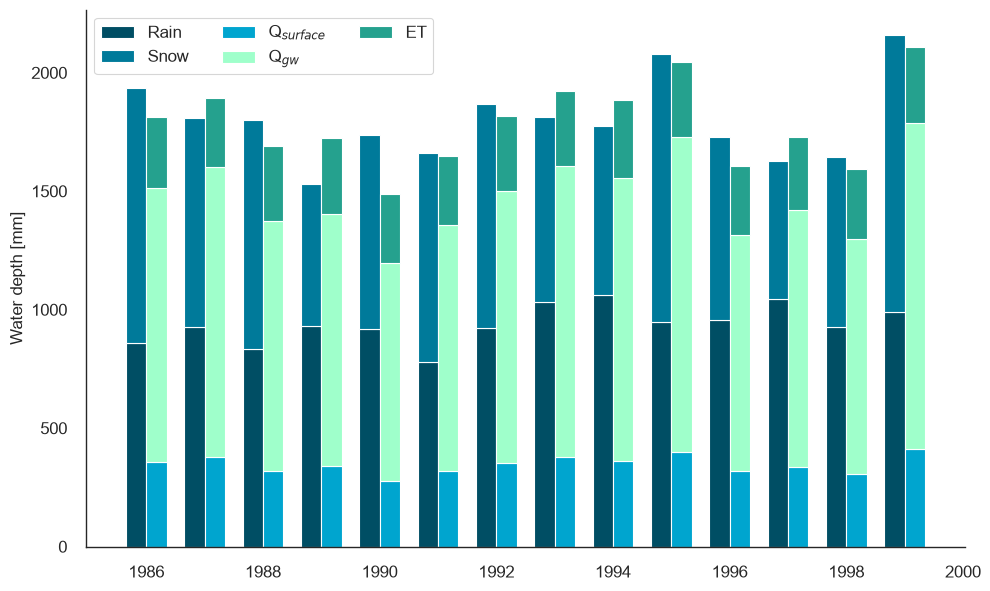

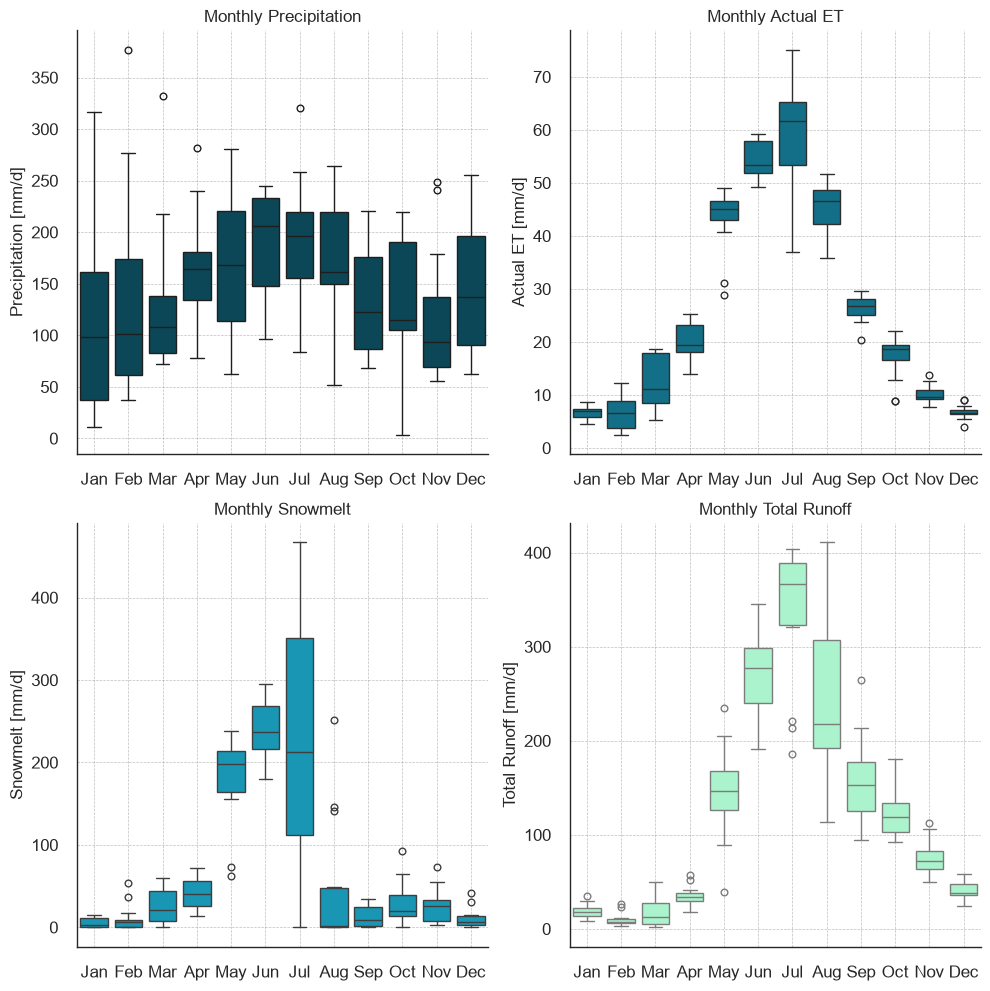

In [103]:
plot_water_balance(results=second_run_results)
plot_monthly_boxplot(results=second_run_results, figsize=(10, 10))

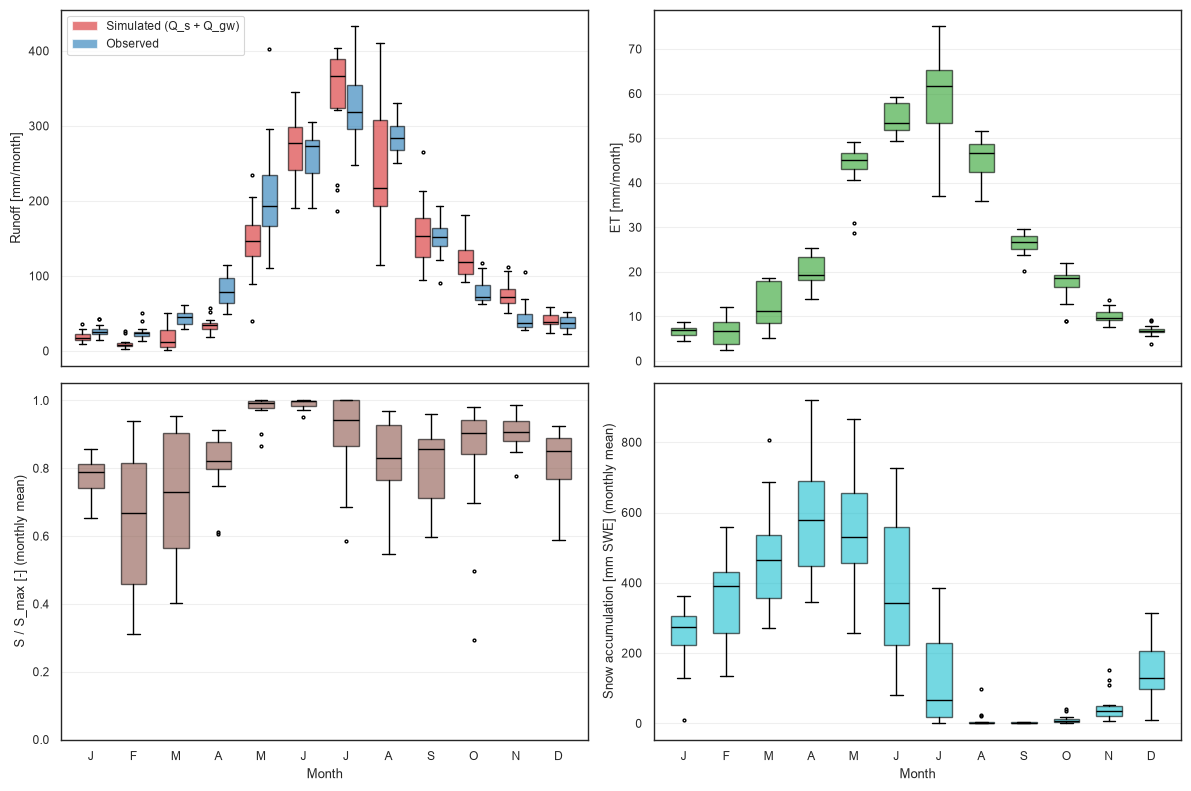

In [104]:
from report_plots import plot_monthly_variable_boxplots  # extra report plots (report_plots.py)

# Monthly boxplots: runoff and ET as monthly totals, S/S_max and snow as monthly means
monthly_stats = plot_monthly_variable_boxplots(second_run_results, S_max=bucket.S_max, observed=data)

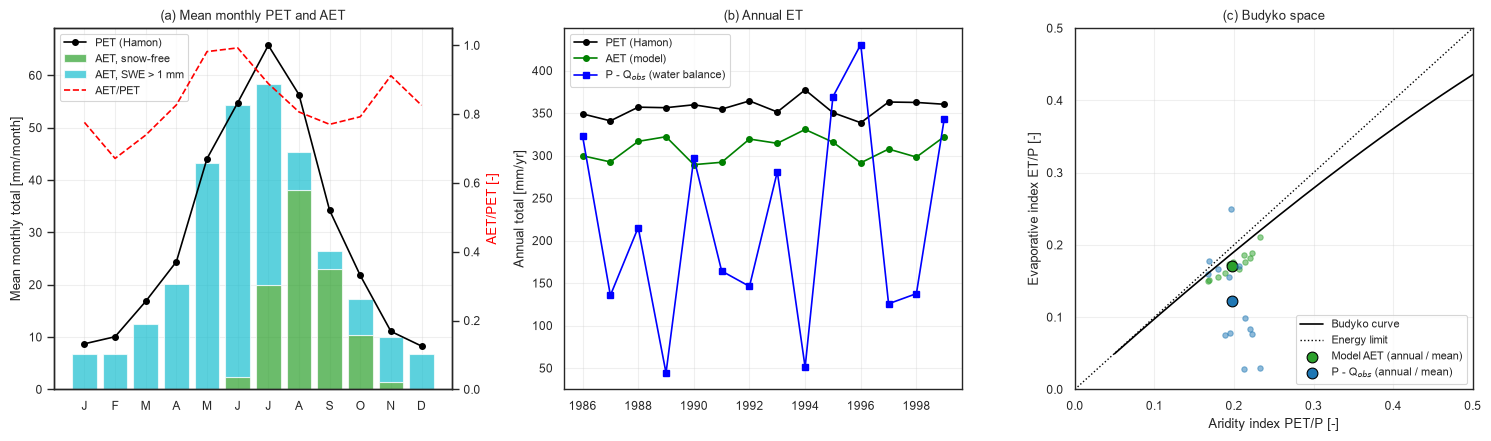

,P,PET,AET,AET_snow,Q_sim,Q_obs,AET/PET,PET/P,AET/P,ET_wb,ET_wb/P
Year,,,,,,,,,,,
1986,1935.20,349.08,299.83,231.11,1513.79,1612.13,0.86,0.18,0.15,323.07,0.17
1987,1809.80,340.88,292.53,235.82,1602.10,1674.33,0.86,0.19,0.16,135.47,0.07
1988,1799.10,356.98,316.71,209.96,1373.35,1583.71,0.89,0.20,0.18,215.39,0.12
1989,1530.80,356.36,322.19,215.74,1403.17,1486.52,0.90,0.23,0.21,44.28,0.03
1990,1739.20,359.79,289.35,158.30,1196.89,1442.10,0.80,0.21,0.17,297.10,0.17
1991,1660.60,354.67,292.12,231.01,1357.03,1496.42,0.82,0.21,0.18,164.18,0.10
1992,1866.60,364.32,319.46,221.41,1498.82,1720.48,0.88,0.20,0.17,146.12,0.08
1993,1812.90,351.32,314.45,221.56,1607.52,1531.97,0.90,0.19,0.17,280.93,0.15
1994,1775.80,377.32,330.75,200.65,1554.14,1724.82,0.88,0.21,0.19,50.98,0.03


In [105]:
from report_plots import compare_aet_pet  # AET vs PET (Hamon), water-balance ET and Budyko plot

# PET is now part of the model output (results["PET"]); AET is results["ET"]
et_stats = compare_aet_pet(second_run_results, observed=data)
et_stats["annual"].round(2)

### Manually Finding a Good Fit

Iteratively change the model parameters until you find a visually good fit. Invest some time to understand how each parameter influences the results. Here is a step-by-step guide to help you with this process:

1. **Define Your New Guess**

   You can define your new guess just like we did for the second guess:

   ```python
   new_guess = {
      'k': 0.2,
      'S_max': 35,
      'fr': 0.2,
      'rg': 17,
      'snow_threshold_temp': 1
   }
   ```

2. **Update model parameters**

   Update the model parameters with your new guess:

   ```python
   model.update_parameters(new_guess)
   ```

3. **Run the model**

   Run the model with the new parameters:

   ```python
   model.run()
   ```


### Elevation-dependent HRUs

The lumped model above treats the whole basin as one unit at 2035 m. Here the same model (same parameter set) is run separately for each HRU from Exercise 1:

- The temperature of each HRU is adjusted from the basin-mean temperature with the lapse rate, using the HRU mean elevation (`basin_mean_elevation` stays at 2035 m, the elevation the input temperature represents).
- Precipitation is the same for all HRUs (the model has no precipitation gradient).
- The basin-total output is the area-weighted sum of the HRU outputs: $Q_{basin} = \sum_i Q_{HRU,i} \cdot A_{HRU,i} / \sum_i A_{HRU,i}$

`hru_table` holds the area and mean elevation of each HRU (team HRU table from Exercise 1). All HRUs use the basin latitude.

In [106]:
# HRU properties from Exercise 1 (team HRU table)
hru_table = pd.DataFrame(
    {
        "HRU": [1, 2, 3, 4, 5],
        "name": ["Glacier", "High Vegetation", "High Bareland", "Low Vegetation", "Low Bareland"],
        "area_km2": [63.32, 85.04, 97.27, 118.87, 19.59],  # contributing area of each HRU [km^2]
        "mean_elevation": [2946, 2175, 2693, 1401, 1365],  # HRU mean elevation [m.a.s.l.]
        "glacier": [True, False, False, False, False],  # glacier-covered HRU (ice melt, see OPTIONAL below)
        "latitude": [None, None, None, None, None],  # HRU centroid latitude [deg N] (optional: None = basin latitude)
    }
)
hru_table

,HRU,name,area_km2,mean_elevation,glacier,latitude
0,1,Glacier,63.32,2946,True,None
1,2,High Vegetation,85.04,2175,False,None
2,3,High Bareland,97.27,2693,False,None
3,4,Low Vegetation,118.87,1401,False,None
4,5,Low Bareland,19.59,1365,False,None


In [107]:
hru_params = {
    # 1: {"k": 3.0},
    # 3: {"k": 2.0, "S_max": 5},
    # 4: {"S_max": 80},
}

In [ ]:
def run_hru_model(model, data, hru_table, basin_area=None, k_ice=None):
    # k_ice: degree-day factor for ice on the glacier HRU; None = use model.k_ice (e.g. from second_guess), 0 = no ice melt
    hru_ids = hru_table["HRU"]
    areas = hru_table["area_km2"]
    elevations = hru_table["mean_elevation"]
    total_area = sum(areas)

    hru_results = {}
    basin_results = None

    for i in range(len(hru_ids)):           
        w = areas[i] / total_area

        hru_model = model.copy()
        hru_model.hru_mean_elevation = elevations[i]
        hru_model.is_glacier = bool(hru_table["glacier"][i])  # ice melt only on the glacier HRU
        if k_ice is not None:
            hru_model.k_ice = k_ice
        if not hru_model.is_glacier:
            hru_model.k_ice = 0.0
        if hru_ids[i] in hru_params:                            
            hru_model.update_parameters(hru_params[hru_ids[i]]) 
        results = hru_model.run(data=data)

        hru_results[hru_ids[i]] = results
        if basin_results is None:
            basin_results = results * w
        else:
            basin_results = basin_results + results * w

    return basin_results, hru_results

In [ ]:
# Run the HRU model with the same parameters as the lumped model (bucket)
# (with spin-up from SPINUP_START; only the evaluation period 1986-1999 is kept)
hru_run_results, hru_results = run_hru_model(
    model=bucket, data=data_spinup, hru_table=hru_table, basin_area=catchment_area, k_ice=0.0  # without ice melt
)
hru_run_results = hru_run_results.loc[data.index]
hru_results = {hru_id: results.loc[data.index] for hru_id, results in hru_results.items()}

# Compare lumped and HRU-based runs
lumped_run_results = run_with_spinup(bucket, data_spinup, data.index)

plot_timeseries(
    results=hru_run_results,
    observed=data,
    
    start_year="1986",
    end_year="1987",
    palette=["red", "blue"],
    monthly=False,
)
plot_water_balance(results=hru_run_results)

In [110]:
# Goodness-of-fit: lumped vs HRU-based model (same parameters)
pd.DataFrame(
    {
        "lumped": score_run(lumped_run_results, data),
        "HRU-based": score_run(hru_run_results, data),
    }
).round(3)

,lumped,HRU-based
nse,0.658,0.669
log_nse,0.650,0.756
kge,0.819,0.668
rmse,2.334,2.296
mae,1.621,1.549
pbias,-6.547,-13.621


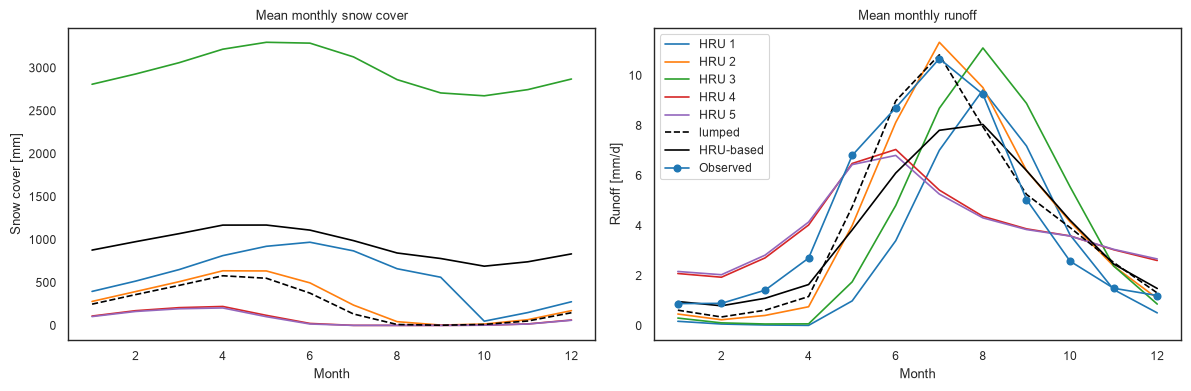

In [111]:
import matplotlib.pyplot as plt

# Elevation effect: mean annual cycle of snow cover and runoff for each HRU
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hru_id, results in hru_results.items():
    monthly = results.groupby(results.index.month).mean()
    axes[0].plot(monthly.index, monthly["Snow_accum"], label=f"HRU {hru_id}")
    axes[1].plot(monthly.index, monthly["Total_Runoff"], label=f"HRU {hru_id}")
for results, label in [(lumped_run_results, "lumped"), (hru_run_results, "HRU-based")]:
    monthly = results.groupby(results.index.month).mean()
    axes[0].plot(monthly.index, monthly["Snow_accum"], "k--" if label == "lumped" else "k-", label=label)
    axes[1].plot(monthly.index, monthly["Total_Runoff"], "k--" if label == "lumped" else "k-", label=label)
axes[0].set(xlabel="Month", ylabel="Snow cover [mm]", title="Mean monthly snow cover")
axes[1].set(xlabel="Month", ylabel="Runoff [mm/d]", title="Mean monthly runoff")
obs_monthly = data["Q"].groupby(data.index.month).mean()
axes[1].plot(obs_monthly.index, obs_monthly, "o-", color="tab:blue", label="Observed")
axes[1].legend()
plt.tight_layout()
plt.show()

### OPTIONAL: glacier ice melt (one process, one parameter `k_ice`)

On the glacier HRU, ice melts once the snow cover is gone: the part of the day left after all snow has melted melts ice with the degree-day factor `k_ice` [mm/°C/d]; there is no ice melt on days with snowfall. On 1 October the snow that survived the summer becomes ice, so snow does not pile up over the years. The ice storage `S_ice` is tracked as a state (negative = glacier mass loss), so the water balance stays closed:

$P = Q + ET + \Delta S_{snow} + \Delta S_{soil} + \Delta S_{gw} + \Delta S_{ice}$

The annual glacier mass balance (hydrological year, October-September) is $B = C - A$ = snowfall − snowmelt − ice melt = $\Delta S_{snow} + \Delta S_{ice}$.

In [ ]:
# k_ice is set in second_guess (bucket.k_ice); k_ice = 0 switches ice melt off
hru_ice_run_results, hru_ice_results = run_hru_model(
    model=bucket, data=data_spinup, hru_table=hru_table, basin_area=catchment_area
)
hru_ice_run_results = hru_ice_run_results.loc[data.index]
hru_ice_results = {hru_id: results.loc[data.index] for hru_id, results in hru_ice_results.items()}

# Goodness-of-fit with and without ice melt (same parameters)
pd.DataFrame(
    {
        "lumped": score_run(lumped_run_results, data),
        "HRU-based": score_run(hru_run_results, data),
        "HRU-based + ice melt": score_run(hru_ice_run_results, data),
    }
).round(3)

In [113]:
# Annual glacier mass balance B = C - A on the glacier HRU (hydrological year Oct-Sep, mm w.e.)
glacier_id = hru_table.loc[hru_table["glacier"], "HRU"].iloc[0]
glacier = hru_ice_results[glacier_id]
hydro_year = (glacier.index.year + (glacier.index.month >= 10)).rename("hydrological year")  # Oct-Dec count to the next year
mass_balance = pd.DataFrame(
    {
        "C (snowfall)": glacier["Snow"],
        "A_snow (snowmelt)": glacier["Snow_melt"],
        "A_ice (ice melt)": glacier["Ice_melt"],
    }
).groupby(hydro_year).sum()
mass_balance["B = C - A"] = mass_balance["C (snowfall)"] - mass_balance["A_snow (snowmelt)"] - mass_balance["A_ice (ice melt)"]
mass_balance = mass_balance.loc[data.index.year[0] + 1 : data.index.year[-1]]  # complete hydrological years only
mass_balance.loc["mean"] = mass_balance.mean()
mass_balance.round(0)

,C (snowfall),A_snow (snowmelt),A_ice (ice melt),B = C - A
hydrological year,,,,
1987,1383.0,638.0,417.0,328.0
1988,1210.0,709.0,55.0,446.0
1989,1184.0,678.0,21.0,484.0
1990,1025.0,691.0,23.0,311.0
1991,1204.0,814.0,114.0,276.0
1992,1255.0,785.0,32.0,438.0
1993,1329.0,632.0,0.0,697.0
1994,1279.0,835.0,0.0,443.0
1995,1622.0,635.0,149.0,839.0


In [ ]:
# Mean monthly runoff: observed vs lumped, HRU-based and HRU-based + ice melt
fig, ax = plt.subplots(figsize=(8, 4))
obs_monthly = data["Q"].groupby(data.index.month).mean()
ax.plot(obs_monthly.index, obs_monthly, "o-", color="tab:blue", label="Observed")
for results, style, label in [
    (lumped_run_results, "k--", "lumped"),
    (hru_run_results, "k-", "HRU-based"),
    (hru_ice_run_results, "r-", f"HRU-based + ice melt (k_ice = {bucket.k_ice})"),
]:
    monthly = results["Total_Runoff"].groupby(results.index.month).mean()
    ax.plot(monthly.index, monthly, style, label=label)
ax.set(xlabel="Month", ylabel="Runoff [mm/d]", title="Mean monthly runoff")
ax.set_xticks(range(1, 13))
ax.legend()
plt.tight_layout()
plt.show()

# WEEK 2: Automatic calibration/validation of the daily water balance model

### Split the data into a training (calibration) and validation set

The `train_size` parameter defines the size of the training set. In the example below we use 80% of the data for training and 20% for validation. Feel free to change that.


In [115]:
train_data, validate_data = train_validate_split(data=data, train_size=0.666)

In [116]:
# Let's have a look at the training data
train_data

,day,P_mix,T_max,T_min,Q
date,,,,,
1986-01-01,1,3.8,-3.4,-12.8,0.513408
1986-01-02,2,0.4,-1.4,-8.8,0.535896
1986-01-03,3,5.7,-3.9,-8.8,0.532298
1986-01-04,4,4.2,-6.5,-14.8,0.525776
1986-01-05,5,4.1,-3.5,-13.2,0.526676
...,...,...,...,...,...
1995-04-24,114,0.4,4.8,1.0,5.132052
1995-04-25,115,37.3,3.3,-2.1,5.087525
1995-04-26,116,15.8,0.7,-2.5,5.889907


In [117]:
# Let's have a look at the validation data
validate_data

,day,P_mix,T_max,T_min,Q
date,,,,,
1995-04-29,119,15.3,7.1,-0.6,4.980931
1995-04-30,120,4.0,2.3,-1.0,5.981884
1995-05-01,121,0.0,6.8,-0.4,5.659852
1995-05-02,122,0.0,8.0,-0.3,6.155044
1995-05-03,123,0.0,9.5,1.2,6.579848
...,...,...,...,...,...
1999-12-27,361,8.1,-0.4,-8.0,1.772077
1999-12-28,362,33.8,-4.5,-9.8,1.430930
1999-12-29,363,8.8,-8.3,-10.8,1.282957


### Automatic Calibration of Model Parameters

To automatically calibrate the model parameters, follow these steps:

1. **Initialize a BucketModelOptimizer**

   This is the first step in the calibration process.

2. **Define the Method**

   You need to define the method that will be used for the calibration: `local` or `n-folds`.

3. **Set the Parameter Bounds**

   Define the bounds for the parameters. This will guide the calibration process.

After setting up, you can start the calibration process. When you call the `calibrate` method, a uniform random guess is sampled from the parameter bounds and the optimization begins. Let's start simple with the local optimization method.


In [118]:
# Initialize the BucketModelOptimizer with the BucketModel instance and observed data
optimizer = BucketModelOptimizer(
    model=bucket, training_data=train_data, validation_data=validate_data
)
# Define the method
method = "local"

# Define the parameter bounds
bounds = {
    "k": (1, 1.5),
    "S_max": (10, 50),
    "fr": (0.0, 0.3),
    "rg": (10, 35),
    "snow_threshold_temp": (-1.0, 4.0),
}

# Now set the options
optimizer.set_options(method=method, bounds=bounds, objective_function="rmse")

BucketModelOptimizer initialized successfully.
Training data shape: (3405, 5)
Validation data shape: (1708, 5)
Optimization configured with method: local
Optimizing for: rmse
Parameter bounds:
    k: [1, 1.5]
    S_max: [10, 50]
    fr: [0.0, 0.3]
    rg: [10, 35]
    snow_threshold_temp: [-1.0, 4.0]


### Now calibrate, it can take up to a minute


In [ ]:
calibrated_parameters, _ = optimizer.calibrate(
    verbose=True, initial_guess=[1.0, 30.79, 0.1, 23.23, 1.88]
)  # For now don't worry about the second output (_)

Starting calibration using local method...
Optimizing for rmse
Starting optimization with initial guess: [1.0, 30.79, 0.1, 23.23, 1.88]
Current parameters: {'k': np.float64(1.1201813943525407), 'S_max': np.float64(30.789754167461687), 'fr': np.float64(0.14807255774101633), 'rg': np.float64(23.22759318139379), 'snow_threshold_temp': np.float64(1.8454088861843039)}
Current rmse: 2.2850
Current parameters: {'k': np.float64(1.1109609737282629), 'S_max': np.float64(30.789697183098376), 'fr': np.float64(0.14640070517179213), 'rg': np.float64(23.22784321397796), 'snow_threshold_temp': np.float64(1.8425074952579306)}
Current rmse: 2.2840
Current parameters: {'k': np.float64(1.1121000233075071), 'S_max': np.float64(30.789580270055747), 'fr': np.float64(0.14522817772266472), 'rg': np.float64(23.22798427986895), 'snow_threshold_temp': np.float64(1.8343361098380793)}
Current rmse: 2.2836
Current parameters: {'k': np.float64(1.1018378753671427), 'S_max': np.float64(30.788131958512132), 'fr': np.flo

### Look at the calibrated parameters


In [ ]:
print("calibrated_parameters:", calibrated_parameters)

calibrated_parameters: {'k': np.float64(1.0), 'S_max': np.float64(29.6414), 'fr': np.float64(0.1259), 'rg': np.float64(24.8356), 'snow_threshold_temp': np.float64(-0.2505)}


### Let's look at the model performance

We will score the model by looking at the Nash-Sutcliffe Efficiency (NSE), the Root Mean Squared Error (RMSE) and the Kling-Gupta Efficiency (KGE). In the `metrics.py` file you can find the formulas for these and other metrics.

The `score_model` function will score the model on the training and validation data separately. Does that make sense to you?


In [ ]:
model_perfomance = optimizer.score_model(metrics=["nse", "rmse", "kge"])

# # Let's have a look at the model performance
# print("model performance:", model_perfomance)


Model Performance Metrics:
--------------------------------------------------
Metric        Training  Validation
--------------------------------------------------
nse             0.6987      0.5341
rmse            2.1676      2.7767
kge             0.7920      0.6879


### Update the model with the calibrated parameters. The optimizer works with a copy of the model, so you need to synchronize the model with the calibrated parameters.


In [ ]:
bucket_calibrated = (
    optimizer.get_optimized_model()
)  # Now your bucket model has the calibrated parameters :)

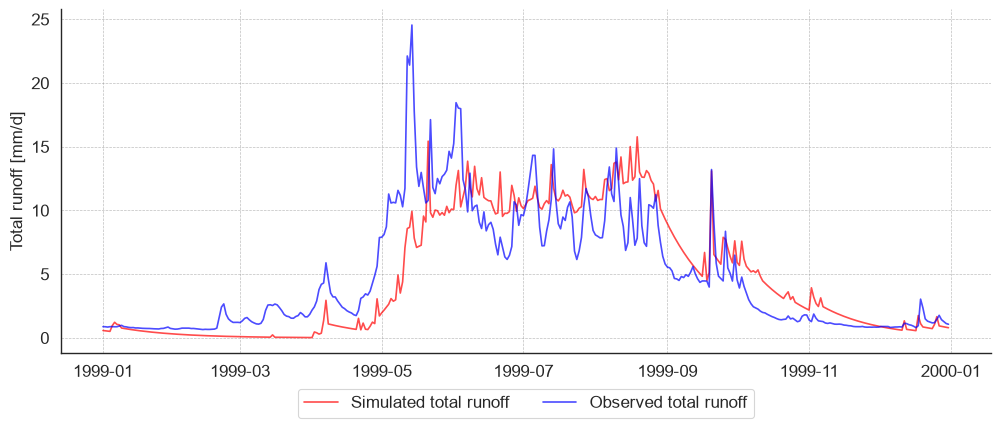

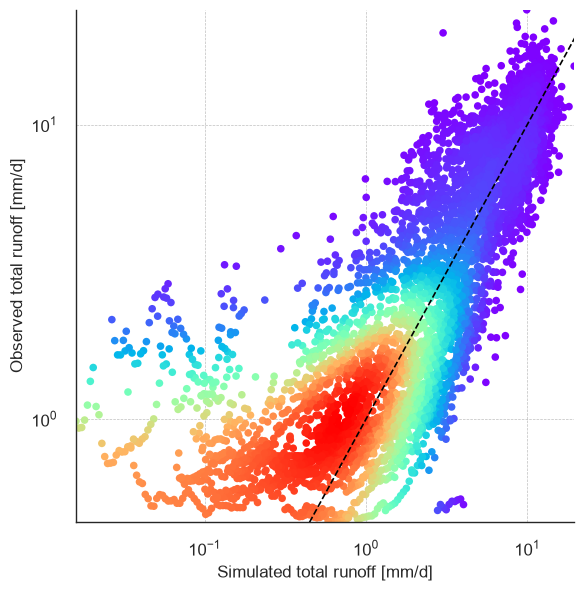

In [ ]:
calibrated_results = bucket_calibrated.run(data=data)
plot_timeseries(
    results=calibrated_results,
    observed=data,
    start_year="1999",
    end_year="2000",
    palette=["red", "blue", "black"],
    plot_precipitation=False,
    output_destination="images/timeseries_with_precip.png",
    figsize=(12, 6),

)
plot_Q_Q(results=calibrated_results, observed=data)

### N-Fold Calibration

In the N-Fold calibration approach, the model is more robustly calibrated by N sampling initial guesses from the parameter bounds. For each sample, the BucketModelOptimizer finds a local minimum, improving the chances of reaching the 'best possible fit' by exploring different starting points. These parameter sets are stored in a DataFrame.

After performing the N-Fold calibration, the best set of parameters is identified using the `get_best_parameters` method. This method evaluates each parameter set based on the RMSE. You can change the metric in the `bucket_model_optimizer.py` file.

Let's try it out


In [ ]:
# Initialize the BucketModelOptimizer with the BucketModel instance and observed data
optimizer = BucketModelOptimizer(
    model=bucket, training_data=train_data, validation_data=validate_data
)
# Define the method
method = "n-folds"

# Define the parameter bounds
bounds = {
    "k": (1, 3),
    "S_max": (10, 50),
    "fr": (0.0, 0.3),
    "rg": (5, 35),
    "snow_threshold_temp": (-1.0, 4.0),
}

# Now set the options
optimizer.set_options(
    method=method, bounds=bounds, folds=5, objective_function="rmse"
)  # Now you need to define the number of folds

BucketModelOptimizer initialized successfully.
Training data shape: (3405, 5)
Validation data shape: (1708, 5)
Optimization configured with method: n-folds
  Using 5 folds for optimization
Optimizing for: rmse
Parameter bounds:
    k: [1, 3]
    S_max: [10, 50]
    fr: [0.0, 0.3]
    rg: [5, 35]
    snow_threshold_temp: [-1.0, 4.0]


Calibration is going to take a while (circa 10 minutes). Be patient :)


In [ ]:
# calibrated_parameters, n_folds_results = optimizer.calibrate()

# # Let's have a look at the n-folds results
# n_folds_results

### Let's look at the parameter distribution


In [ ]:
plot_parameter_kde(n_fold_results=n_folds_results, bounds=bounds)

NameError: name 'n_folds_results' is not defined

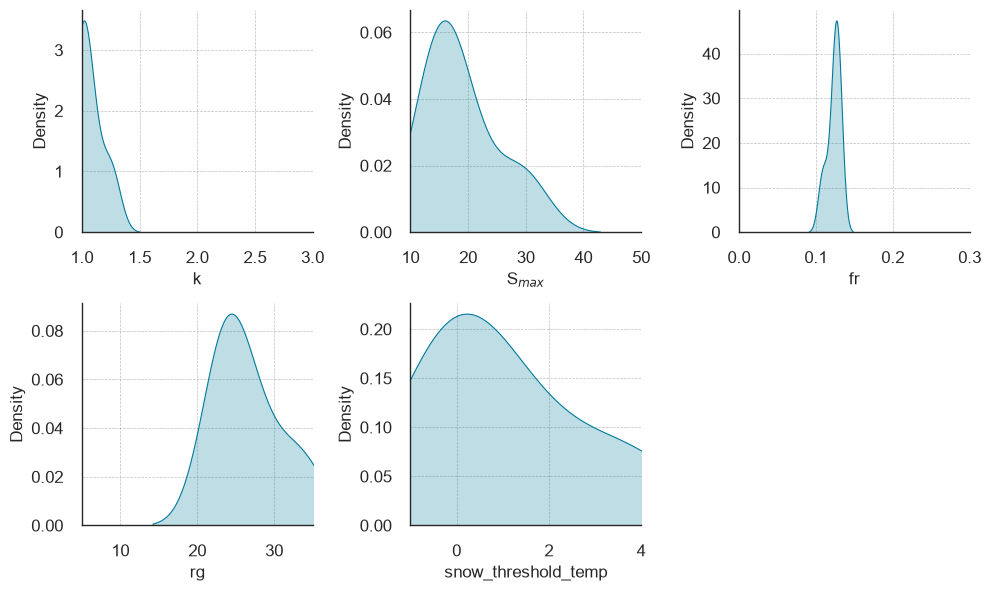

In [ ]:
plot_parameter_kde(n_fold_results=n_folds_results, bounds=bounds, plot_type="kdeplot")

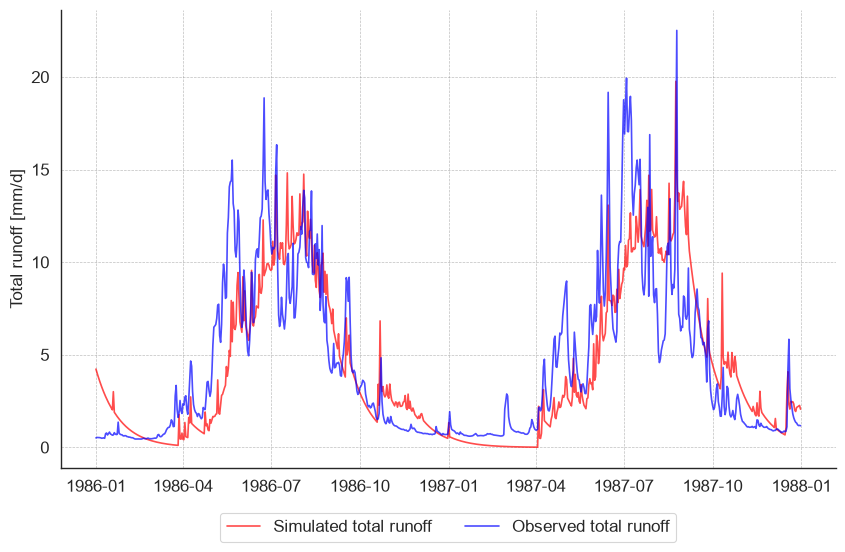

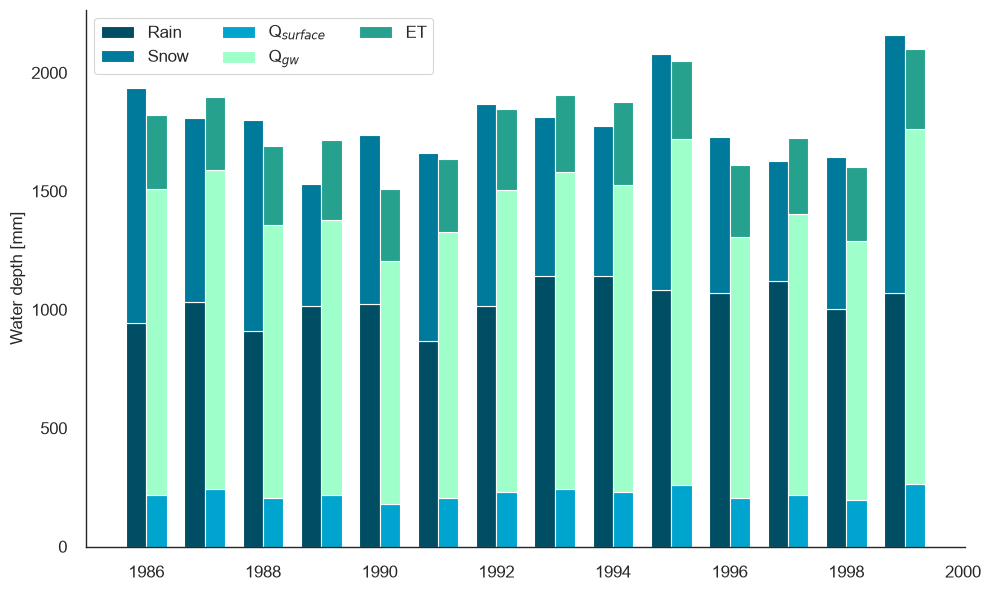

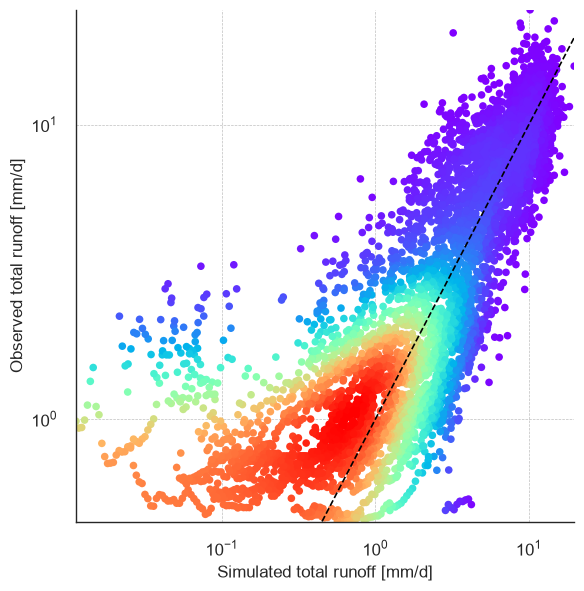

In [ ]:
images_folder = "images_new_data"

# Let's sync the models
n_fold_calibrated_model = optimizer.get_optimized_model()

final_run = n_fold_calibrated_model.run(data=data)

# plot_timeseries(
#     results=final_run,
#     observed=data,
#     start_year="1986",
#     end_year="2000",
#     palette=["red", "blue"],
#     monthly=True,
# )
plot_timeseries(
    results=final_run,
    observed=data,
    start_year="1986",
    end_year="1987",
    palette=["red", "blue"],
)
plot_water_balance(results=final_run)
plot_Q_Q(results=final_run, observed=data)

In [ ]:
# Let's look at the best parameters:
print(n_fold_calibrated_model)
print(calibrated_parameters)

{'k': 1.0, 'S_max': 14.9406, 'fr': 0.1289, 'rg': 23.6674, 'snow_threshold_temp': -0.0665}


### Let's look at model performance


In [ ]:
calibrated_model_perfromance = optimizer.score_model(metrics=["nse", "rmse", "kge"])



Model Performance Metrics:
--------------------------------------------------
Metric        Training  Validation
--------------------------------------------------
nse             0.7016      0.5461
rmse            2.1570      2.7408
kge             0.8080      0.7076


### WEEK 3: Local parameter sensitivity

To be discussed


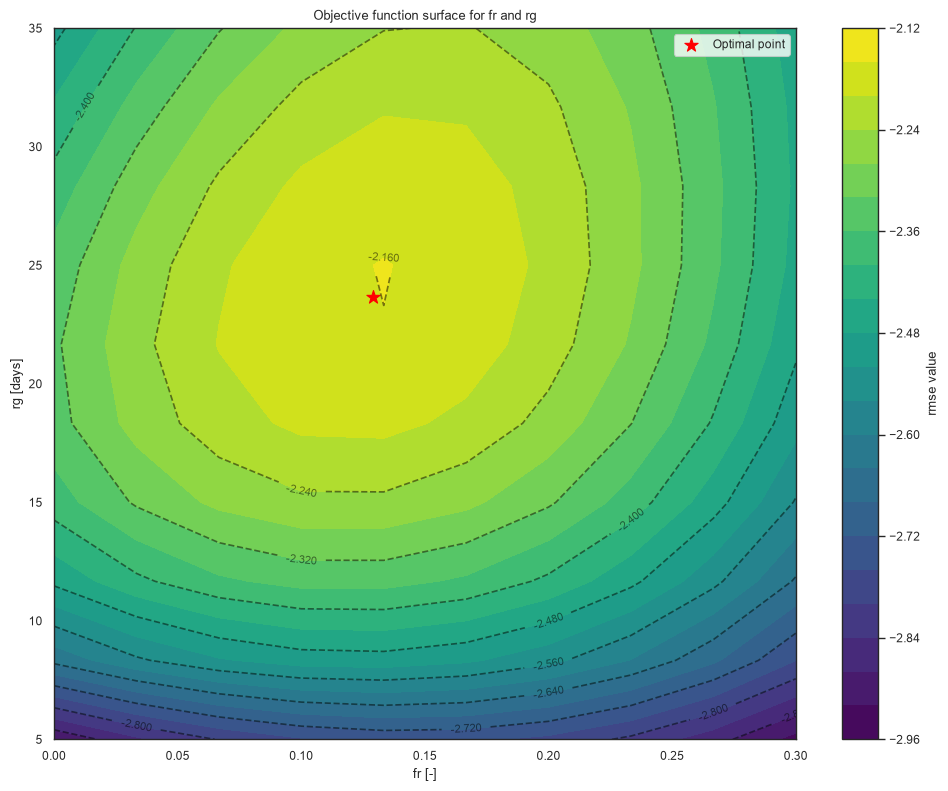

In [ ]:
optimizer.plot_objective_surface(
    param1="fr", param2="rg", n_points=10
)

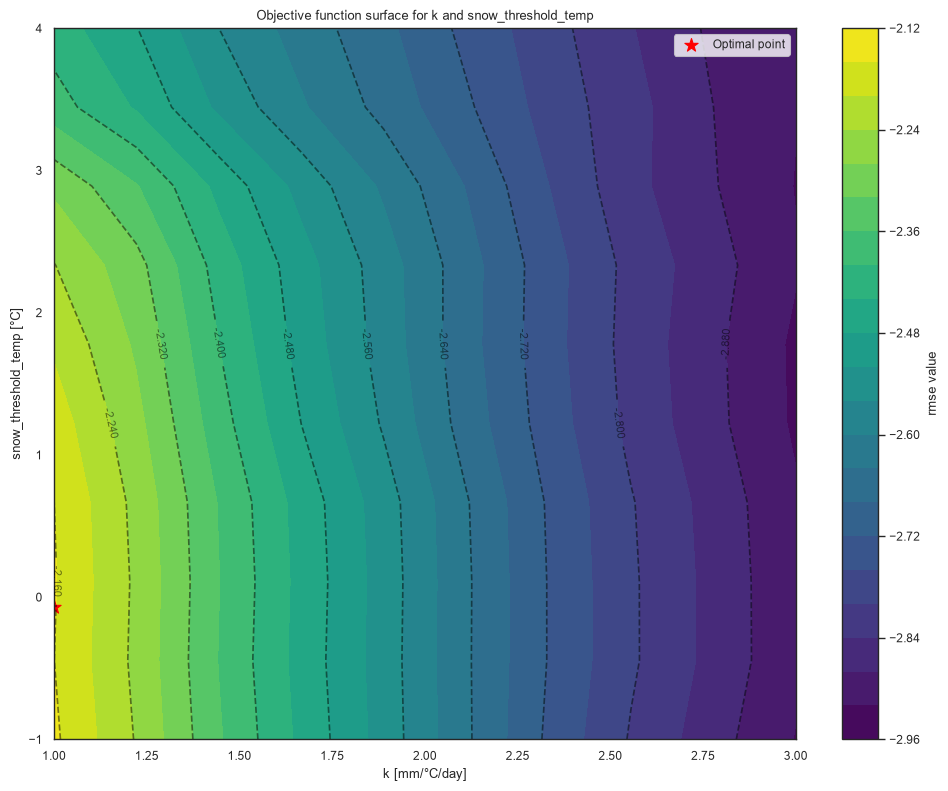

In [ ]:
optimizer.plot_objective_surface(
    param1="k",
    param2="snow_threshold_temp",
    n_points=10,
)

In [ ]:
optimizer.local_sensitivity_analysis()

,Parameter,Sensitivity_Pos,Sensitivity_Neg,Average_Sensitivity
0,k,0.0117,0.0190,0.0153
1,S_max,-0.0144,-0.0153,0.0149
3,rg,-0.0013,-0.0013,0.0013
2,fr,0.0008,0.0008,0.0008
4,snow_threshold_temp,0.0000,-0.0000,0.0000
